# Lab: Data Visualization and Visual Thinking

The U.S. Bureau of Transportation Statistics collects information about scheduled domestic flights. In this lab, you will use the ideas from **Data Visualization and Visual Thinking** to examine a documented sample of 5,000 completed, non-diverted flights from May 2026.


## Learning goals

By the end of this lab, you should be able to:

- load and inspect a CSV file as a Pandas DataFrame;
- distinguish Pandas data types from quantitative and categorical feature types;
- check for missing values;
- create and label a histogram and a bar chart;
- describe a distribution by its typical values, range, and skew;
- use `.describe()` to check estimates made from a histogram;
- explain how histogram bins and axis scales affect a figure; and
- identify conclusions that can and cannot be supported by a sample; and
- find a documented dataset, audit every feature, and interpret its quantitative and categorical distributions.


## Using AI tools responsibly

You may use an AI tool to ask questions, debug code, or receive feedback. You are still responsible for understanding every part of your submission and checking suggestions against your notebook's output. At the end of the lab, disclose whether you used an AI tool and how you evaluated its advice.


## Dataset

The [U.S. Bureau of Transportation Statistics (BTS) Reporting Carrier On-Time Performance data](https://www.transtats.bts.gov/DL_SelectFields.aspx?QO_fu146_anzr=b0-gvzr&gnoyr_VQ=FGJ) contains 611,735 reported domestic flight records for May 2026. Completed, non-diverted flights with recorded values for all five selected features were eligible for this lab. Canceled flights, diverted flights, and records missing any selected feature were excluded before the sample was drawn.

The dataset is a reproducible random sample of 5,000 eligible flights. Each observation represents one completed, non-diverted domestic flight in that sample. Because incomplete records were removed before sampling, finding no missing values in the dataset does not mean that the original BTS data had no missing values. Conclusions from this sample describe the eligible flights and should not automatically be generalized to canceled or diverted flights.

| Feature | Description |
| --- | --- |
| `airline` | Airline that reported the flight |
| `origin_city` | Departure city |
| `destination_city` | Arrival city |
| `distance_miles` | Nonstop flight distance in miles |
| `arrival_delay_minutes` | Minutes between scheduled and actual arrival; negative values mean the flight arrived early |


## Load and preview the data

Import Pandas using the conventional alias `pd`. Read `data/bts_flights_may_2026_sample.csv` into a DataFrame named `flights`.


In [5]:
import pandas as pd

flights = pd.read_csv("data/bts_flights_may_2026_sample.csv")

flights.head()

,airline,origin_city,destination_city,distance_miles,arrival_delay_minutes
0,Alaska Airlines,"Anchorage, AK","Chicago, IL",2846,65
1,Alaska Airlines,"Anchorage, AK","Cordova, AK",160,-1
2,Alaska Airlines,"Anchorage, AK","Fairbanks, AK",261,-18
3,Alaska Airlines,"Anchorage, AK","Juneau, AK",571,-21
4,Alaska Airlines,"Anchorage, AK","Juneau, AK",571,-14


Display the first five rows of the DataFrame.


In [6]:
flights.head

<bound method NDFrame.head of               airline                     origin_city destination_city  \
0     Alaska Airlines                   Anchorage, AK      Chicago, IL   
1     Alaska Airlines                   Anchorage, AK      Cordova, AK   
2     Alaska Airlines                   Anchorage, AK    Fairbanks, AK   
3     Alaska Airlines                   Anchorage, AK       Juneau, AK   
4     Alaska Airlines                   Anchorage, AK       Juneau, AK   
...               ...                             ...              ...   
4995  United Airlines  West Palm Beach/Palm Beach, FL      Chicago, IL   
4996  United Airlines  West Palm Beach/Palm Beach, FL      Houston, TX   
4997  United Airlines  West Palm Beach/Palm Beach, FL      Houston, TX   
4998  United Airlines  West Palm Beach/Palm Beach, FL       Newark, NJ   
4999  United Airlines  West Palm Beach/Palm Beach, FL       Newark, NJ   

      distance_miles  arrival_delay_minutes  
0               2846               

Display the last five rows of the DataFrame.


In [7]:
flights.tail

<bound method NDFrame.tail of               airline                     origin_city destination_city  \
0     Alaska Airlines                   Anchorage, AK      Chicago, IL   
1     Alaska Airlines                   Anchorage, AK      Cordova, AK   
2     Alaska Airlines                   Anchorage, AK    Fairbanks, AK   
3     Alaska Airlines                   Anchorage, AK       Juneau, AK   
4     Alaska Airlines                   Anchorage, AK       Juneau, AK   
...               ...                             ...              ...   
4995  United Airlines  West Palm Beach/Palm Beach, FL      Chicago, IL   
4996  United Airlines  West Palm Beach/Palm Beach, FL      Houston, TX   
4997  United Airlines  West Palm Beach/Palm Beach, FL      Houston, TX   
4998  United Airlines  West Palm Beach/Palm Beach, FL       Newark, NJ   
4999  United Airlines  West Palm Beach/Palm Beach, FL       Newark, NJ   

      distance_miles  arrival_delay_minutes  
0               2846               

## Inspect the DataFrame

Display a summary of the DataFrame that includes the feature names, the number of non-missing values, and the Pandas data types.


In [8]:
flights.info

<bound method DataFrame.info of               airline                     origin_city destination_city  \
0     Alaska Airlines                   Anchorage, AK      Chicago, IL   
1     Alaska Airlines                   Anchorage, AK      Cordova, AK   
2     Alaska Airlines                   Anchorage, AK    Fairbanks, AK   
3     Alaska Airlines                   Anchorage, AK       Juneau, AK   
4     Alaska Airlines                   Anchorage, AK       Juneau, AK   
...               ...                             ...              ...   
4995  United Airlines  West Palm Beach/Palm Beach, FL      Chicago, IL   
4996  United Airlines  West Palm Beach/Palm Beach, FL      Houston, TX   
4997  United Airlines  West Palm Beach/Palm Beach, FL      Houston, TX   
4998  United Airlines  West Palm Beach/Palm Beach, FL       Newark, NJ   
4999  United Airlines  West Palm Beach/Palm Beach, FL       Newark, NJ   

      distance_miles  arrival_delay_minutes  
0               2846             

**How many observations are in the DataFrame?**

Your answer: first and last 5 so 10


Count the missing values in every feature.


In [9]:
flights.isnull().sum()

airline                  0
origin_city              0
destination_city         0
distance_miles           0
arrival_delay_minutes    0
dtype: int64

## Classify the features

A **quantitative feature** records an amount or measurement for which arithmetic is meaningful. A **categorical feature** assigns observations to groups or labels.


**Complete the table with the Pandas data type, feature type, and number of missing values for each feature. Use `.info()` and `.isnull().sum()`; enter 0 when no values are missing.**

| Feature | Pandas data type | Feature type | Number of missing values |
| --- | --- | --- | ---: |
| `airline` |  |  |  |
| `origin_city` |  |  |  |
| `destination_city` |  |  |  |
| `distance_miles` |  |  |  |
| `arrival_delay_minutes` |  |  |  |


## Which destination city is most common in the sample?

Calculate and display the frequency of each destination city. Save the result as `destination_counts`.


In [10]:
destination_counts = flights["destination_city"].value_counts()

display(destination_counts)

destination_city
Chicago, IL                      296
Atlanta, GA                      222
Dallas/Fort Worth, TX            210
Denver, CO                       209
Washington, DC                   165
                                ... 
Watertown, SD                      1
Cedar City, UT                     1
Sun Valley/Hailey/Ketchum, ID      1
Carlsbad, CA                       1
Redding, CA                        1
Name: count, Length: 238, dtype: int64

Import `matplotlib.pyplot` using the conventional alias `plt`. Use `.head(10)` on `destination_counts` to select the ten most frequent destination cities, then create a bar chart. Give the figure a descriptive title and label both axes.


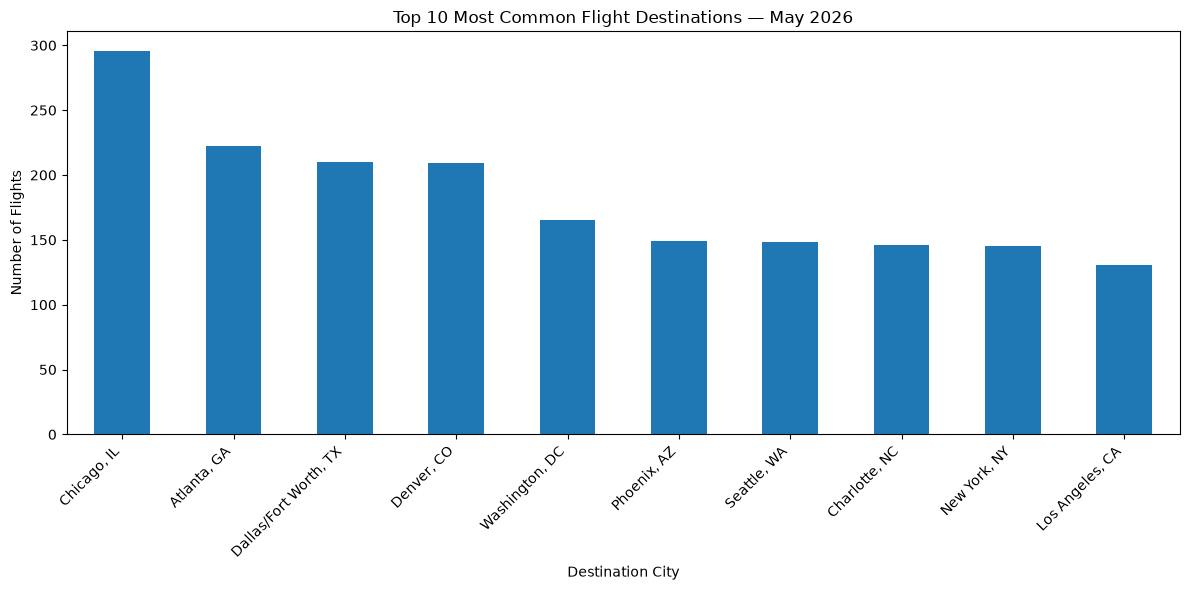

In [11]:
import matplotlib.pyplot as plt

top_10 = destination_counts.head(10)

plt.figure(figsize=(12, 6))
top_10.plot(kind="bar")

plt.title("Top 10 Most Common Flight Destinations — May 2026")
plt.xlabel("Destination City")
plt.ylabel("Number of Flights")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Which destination city is most common in the sample?**

Your answer: Chicago, IL


## What was the distribution of arrival delays?

Negative values represent early arrivals, zero represents an on-time arrival, and positive values represent late arrivals.

Create a histogram of `arrival_delay_minutes` using the default number of bins. Give the figure a descriptive title and label both axes.


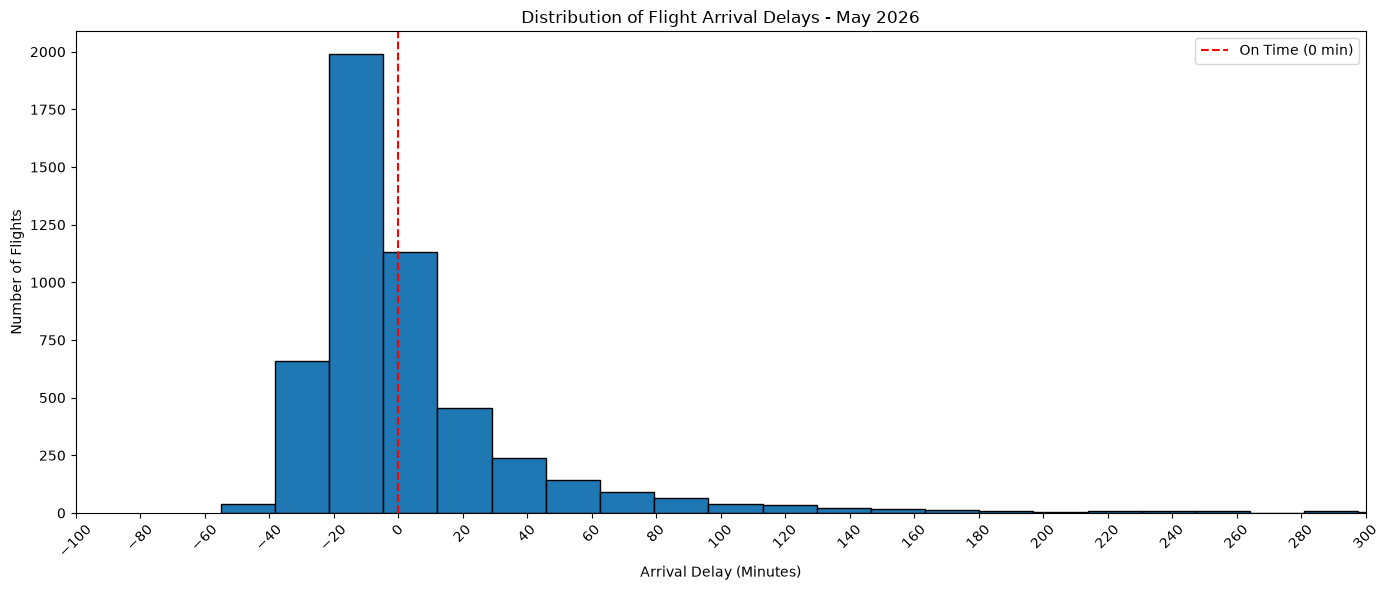

In [12]:
import matplotlib.pyplot as plt
import numpy as np

delays = flights["arrival_delay_minutes"]

plt.figure(figsize=(14, 6))

plt.hist(delays, bins=60, edgecolor="black")

plt.title("Distribution of Flight Arrival Delays - May 2026")
plt.xlabel("Arrival Delay (Minutes)")
plt.ylabel("Number of Flights")

plt.xticks(np.arange(-100, 301, 20), rotation=45)
plt.xlim(-100, 300)
plt.axvline(0, color="red", linestyle="--", label="On Time (0 min)")
plt.legend()

plt.tight_layout()
plt.show()



**Approximately what arrival-delay value appears most common?**

Your answer: 0-20 Among flights that arrived late, the most common arrival-delay range appears to be approximately 0 to 20 minutes.
For the entire dataset, including early flights, the histogram suggests approximately −20 to 0 minutes.

**What is the approximate range from the smallest to the largest arrival-delay value?**

Your answer:  We need the actual data because our graph was zoomed to −100 through +300 minutes.


**Does the arrival-delay distribution appear symmetric or skewed?**

Your answer:  The distribution is right-skewed. Most flights arrived either slightly early or with relatively short delays, while fewer flights experienced very long delays. These larger positive values create a long tail extending to the right.


Display a numerical summary of `arrival_delay_minutes`.


In [13]:
flights["arrival_delay_minutes"].describe()

count    5000.000000
mean        6.098800
std        48.335493
min       -55.000000
25%       -16.000000
50%        -6.000000
75%        10.000000
max       953.000000
Name: arrival_delay_minutes, dtype: float64

Calculate and display the exact mode of `arrival_delay_minutes` using `.mode()`.


In [14]:
flights["arrival_delay_minutes"].mode()

0   -8
Name: arrival_delay_minutes, dtype: int64

In [15]:
late_flights = flights[flights["arrival_delay_minutes"] > 0]

late_flights["arrival_delay_minutes"].mode()

0    2
Name: arrival_delay_minutes, dtype: int64

**How closely did the calculated mode match the most common value you estimated from the histogram?**

Your answer:  The exact mode was -8 minutes, meaning flights arrived 8 minutes early most frequently. This falls within the -20 to 0 minute interval that had the highest frequency in the full histogram. When looking only at late arrivals, the mode was 2 minutes, which falls within my estimated 0 to 20 minute delay range.


**How closely did the minimum and maximum from `.describe()` match the range you estimated from the histogram?**

Your answer:  The minimum was -55 minutes, which matched the lower end of the visible distribution fairly closely. However, the maximum was 953 minutes, much greater than the 300-minute upper limit displayed on my histogram. This showed me that limiting the axis range concealed some of the extreme delays and made the overall range appear smaller than it actually was.


**Is the mean greater than, less than, or approximately equal to the median?**

Your answer:  The mean is greater than the median. The mean arrival delay was approximately +6.10 minutes, while the median was -6 minutes, a difference of about 12.10 minutes.


**How is the relationship between the mean and median connected to the histogram's shape?**

Your answer:  The mean is greater than the median because the distribution is right-skewed. Most flights arrived relatively close to their scheduled times, but some experienced extremely long delays. Those large positive values pulled the mean upward, while the median remained at -6 minutes because it is less affected by extreme values. This explains why the average flight was slightly late even though the median flight arrived early.

## Applying the principles: histogram bins

Re-create the arrival-delay histogram using exactly 5 bins.


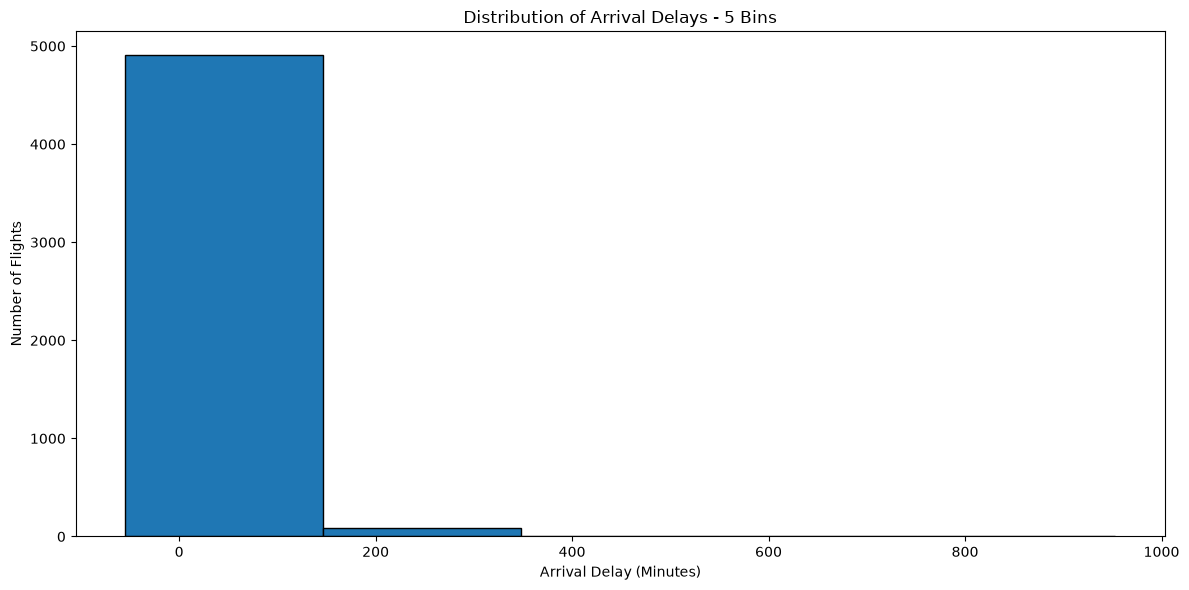

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.hist(flights["arrival_delay_minutes"], bins=5, edgecolor="black")

plt.title("Distribution of Arrival Delays - 5 Bins")
plt.xlabel("Arrival Delay (Minutes)")
plt.ylabel("Number of Flights")

plt.tight_layout()
plt.show()

Re-create the arrival-delay histogram using exactly 25 bins.


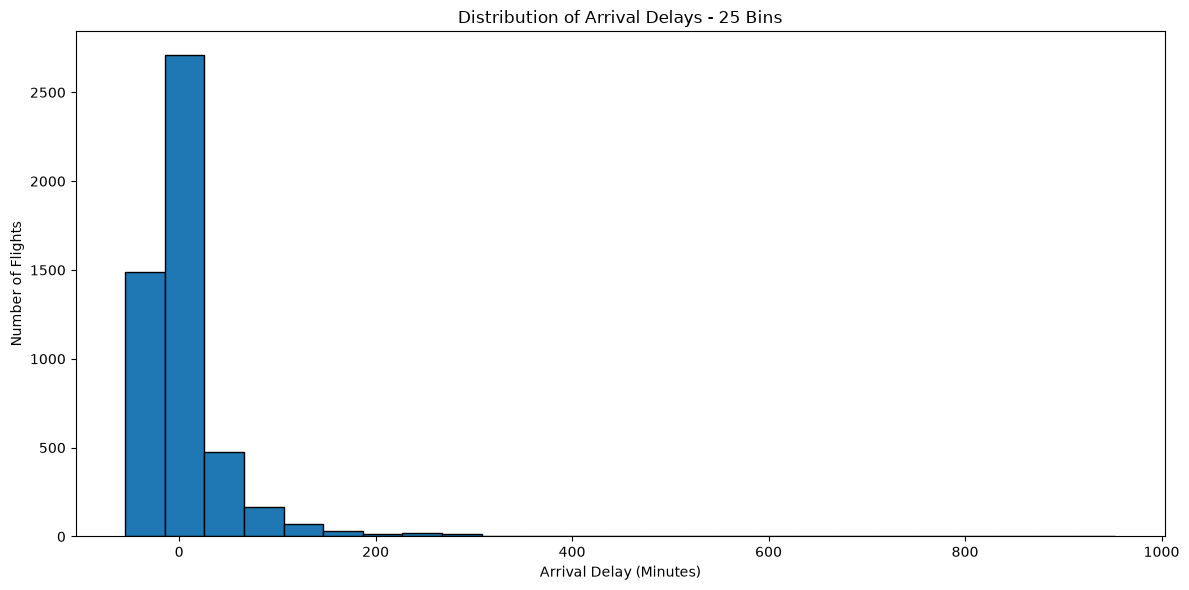

In [17]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.hist(flights["arrival_delay_minutes"], bins=25, edgecolor="black")

plt.title("Distribution of Arrival Delays - 25 Bins")
plt.xlabel("Arrival Delay (Minutes)")
plt.ylabel("Number of Flights")

plt.tight_layout()
plt.show()


**What changed when the number of bins was reduced to 5?**

Your answer:  Reducing the histogram to 5 bins grouped the arrival delays into much larger intervals. Almost all 5,000 flights appeared in the first bar, making it difficult to distinguish early arrivals from shorter delays. The graph still showed that most flights were concentrated near the lower end, but it concealed much of the detail in the distribution.

**What changed when the number of bins was increased to 25?**

Your answer:  Increasing the histogram to 25 bins created narrower intervals, making the distribution easier to examine. I could see more variation among the arrival delays and better identify where most flights were concentrated. The long right tail was also more apparent, although the extreme delays still compressed most of the data toward the left side of the graph.

**Which bin setting communicates the distribution most clearly?**

Your answer:  I believe the 25-bin histogram communicates the distribution more clearly. The 5-bin version combines too many arrival times into broad categories and hides important differences. With 25 bins, the graph provides a better balance of detail and readability, allowing me to identify the concentration of flights and the right-skewed distribution more easily.

## Applying the principles: a misleading vertical axis

Run both cells below and compare the figures.


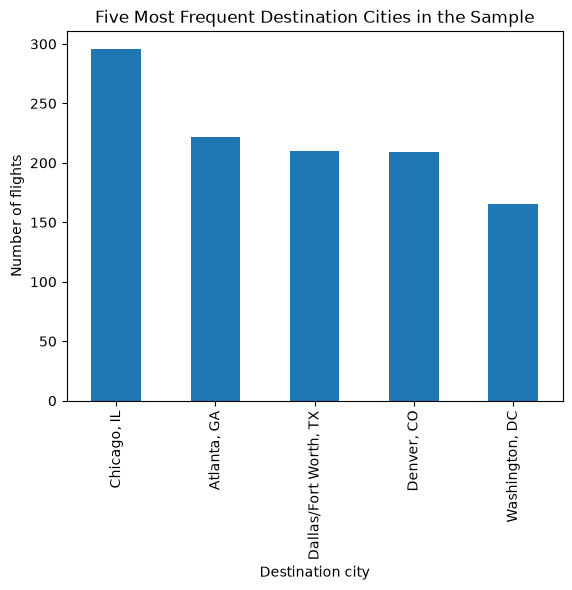

In [18]:
top_destinations = destination_counts.head(5)
top_destinations.plot(kind="bar")
plt.title("Five Most Frequent Destination Cities in the Sample")
plt.xlabel("Destination city")
plt.ylabel("Number of flights")
plt.show()


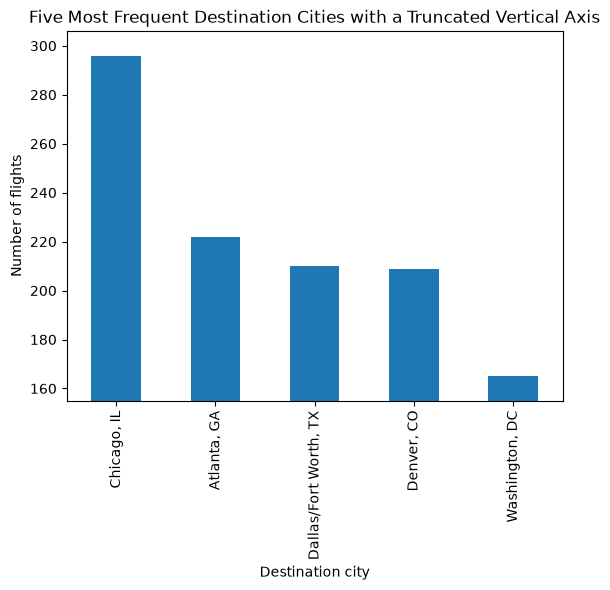

In [19]:
top_destinations.plot(kind="bar")
plt.ylim(top_destinations.min() - 10, top_destinations.max() + 10)
plt.title("Five Most Frequent Destination Cities with a Truncated Vertical Axis")
plt.xlabel("Destination city")
plt.ylabel("Number of flights")
plt.show()


**How does the truncated axis change the apparent differences among the destination cities?**

Your answer:  The truncated vertical axis makes the differences between destination cities look much larger than they really are. By starting the axis above zero, the chart exaggerates the differences in the heights of the bars. Even relatively small differences in flight counts can appear significant, which could mislead someone interpreting the data.

**Which chart communicates the counts more honestly?**

Your answer:  The original chart with the vertical axis starting at zero communicates the counts more honestly. It shows the actual differences in flight frequencies without exaggerating them. The truncated chart makes the differences seem more dramatic, even though the underlying data hasn't changed.

## Is this sample representative?

Review the dataset description at the top of the lab before answering these questions.


**What time period is represented by the source data?**

Your answer:  The source data represents domestic flights in the United States during May 2026.

**Which flights were eligible to be included in the sample?**

Your answer:  Completed, non-diverted domestic flights from May 2026 that had recorded values for all five selected features were eligible. A random sample of 5,000 flights was selected from those records.

**Which flights and records were excluded before the sample was selected?**

Your answer:  Canceled flights, diverted flights, and records missing any of the five selected features were excluded before the sample was drawn.

**Does finding no missing values in the sample prove that the original BTS data had no missing values?**

Your answer:  No. The original dataset could still contain missing values because incomplete records were removed before the sample was selected. Finding no missing values only confirms that the selected sample contains complete records for the five features being analyzed.

**Why should conclusions from this sample not automatically be generalized to canceled or diverted flights?**

Your answer:  The sample only represents completed, non-diverted domestic flights with complete data from May 2026. It excludes canceled flights, diverted flights, and incomplete records. It also covers only one month, so the patterns may not represent other seasons or the entire year. Generalizing these findings to all flights could lead to inaccurate conclusions.

## Choosing a chart

Choose a histogram, bar chart, or pie chart for each question. Use the question and number of categories to justify your choice.


**Which chart would you use to show the frequency of each airline?**

Your answer:  A bar chart is best because airlines are categorical values, and a bar chart makes it easy to compare their flight counts

**Which chart would you use to show what proportion of sampled flights were early, on time, and delayed? Use arrival delays below 0, equal to 0, and above 0 minutes, respectively.**

Your answer:  A pie chart is appropriate because there are only three categories, and it shows each category's proportion of the total 5,000 flights.

**Which chart would you use to show the distribution of flight distances?**

Your answer:  A histogram is best because flight distance is a quantitative measurement in miles. A histogram shows how the distances are distributed across numerical intervals.

## Explore a dataset of your own

Apply the same inspection and visualization process to a different dataset that interests you.

### 1. Find and describe your dataset

Start with [Kaggle Datasets](https://www.kaggle.com/datasets), the [UCI Machine Learning Repository](https://archive.ics.uci.edu/), or [Data.gov](https://catalog.data.gov/). You can also search a city or state open-data portal. Search for a topic you enjoy, such as sports, music, animals, transportation, or the environment.

Choose a manageable CSV file with a data dictionary (or equivalent feature documentation), at least one quantitative feature, and at least one categorical feature with a manageable number of categories. Use a different dataset from the flights and penguins already used in class. Save the file in this notebook's `data` folder.

Read the data dictionary before choosing your features. In a short paragraph, describe the dataset's subject, what one row represents, and its time period and geographic coverage if documented. Include its title, publisher or creator, a direct link to the dataset, and a link to the data dictionary. State when information is not documented instead of guessing.


**Dataset description and source links:**

Your answer:  **Dataset Title:** Global Spiritual Identity — Religious and Spiritual Self-Identification Across Countries

**Source:** Our World in Data, using information from the Global Flourishing Study.

**Dataset Link:** https://ourworldindata.org/grapher/share-of-people-who-identify-as-religious-or-spiritual

**Source Documentation:** https://ourworldindata.org/grapher/share-of-people-who-identify-as-religious-or-spiritual

I chose this dataset because I'm interested in consciousness, spirituality, and how people's beliefs and understanding of themselves differ across the world. My goal is to investigate whether international patterns in spiritual identification might offer insight into the broader idea of spiritual awakening.

The dataset examines how people identify themselves as religious, spiritual, both religious and spiritual, or neither. Each row represents one country, with percentages describing the responses of people surveyed there. The data represents 2023 survey observations covering 22 countries.

The dataset contains categorical information, such as country names, and quantitative information, such as the percentages identifying with different spiritual or religious categories.

The CSV used for this analysis was reconstructed from the published Our World in Data chart because the original CSV download was inaccessible. The values are approximate rather than original survey records.

Although spiritual identification cannot prove that someone has experienced a spiritual awakening, analyzing these patterns may provide a useful starting point for understanding differences in spiritual identity across countries.


### 2. Load the data and describe every feature

Load your CSV into a new DataFrame with a descriptive name ending in `_df`, such as `movies_df`, `weather_df`, or `animals_df`. Choose a name that describes your dataset and use it consistently throughout your analysis. Display its first five rows, shape, `.info()`, and `.isnull().sum()` to inspect its features, storage types, and missing values. Use a relative path so your notebook can run on another computer.


In [20]:
import pandas as pd

spiritual_df = pd.read_csv(
    "data/global_spiritual_identity_chart_derived.csv"
)

display(spiritual_df.head())

print("Dataset shape:", spiritual_df.shape)

spiritual_df.info()

print("\nMissing values by feature:")
print(spiritual_df.isnull().sum())

,country,year,religious_only_pct,both_religious_and_spiritual_pct,spiritual_only_pct,neither_pct,no_answer_pct,spiritual_or_both_pct
0,India,2023,63.0,21.7,5.9,7.9,1.5,27.6
1,Nigeria,2023,54.8,27.0,11.7,5.8,0.7,38.7
2,Turkey,2023,52.8,10.2,4.6,27.9,4.5,14.8
3,Egypt,2023,49.8,11.5,4.1,32.5,2.1,15.6
4,Brazil,2023,39.4,18.0,18.9,22.5,1.3,36.9


Dataset shape: (22, 8)
<class 'pandas.DataFrame'>
RangeIndex: 22 entries, 0 to 21
Data columns (total 8 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   country                           22 non-null     str    
 1   year                              22 non-null     int64  
 2   religious_only_pct                22 non-null     float64
 3   both_religious_and_spiritual_pct  22 non-null     float64
 4   spiritual_only_pct                22 non-null     float64
 5   neither_pct                       22 non-null     float64
 6   no_answer_pct                     22 non-null     float64
 7   spiritual_or_both_pct             22 non-null     float64
dtypes: float64(6), int64(1), str(1)
memory usage: 1.5 KB

Missing values by feature:
country                             0
year                                0
religious_only_pct                  0
both_religious_and_spiritual_pct    0
spiritual_only_pct

Complete the table below with **one row for every feature** in your dataset. Add as many rows as needed. Use the data dictionary to summarize what each feature means, including units or category-code meanings where relevant.

- **Data type:** quantitative or categorical; identify identifiers and date/time features explicitly when appropriate. A numeric identifier is not a quantitative measurement.
- **Data storage type:** the actual Pandas dtype shown by `.info()` or `.dtypes`, such as `int64`, `float64`, `object`, `str`, or `datetime64[ns]`.
- **Missing values:** the number reported for that feature, including 0 when there are none. Count missing values before removing records. If the dictionary defines special missing codes, such as -999 or "Unknown", explain how you handle those codes and make sure the counts reflect that decision.


| Feature | Description from the data dictionary (including units/codes) | Data type | Data storage type | Number of missing values |
|---|---|---|---|---:|
| country | Country represented by the survey results | Categorical | str | 0 |
| year | Survey observation year (2023) | Date/time (year) | int64 | 0 |
| religious_only_pct | Percentage identifying as religious but not spiritual | Quantitative | float64 | 0 |
| both_religious_and_spiritual_pct | Percentage identifying as both religious and spiritual | Quantitative | float64 | 0 |
| spiritual_only_pct | Percentage identifying as spiritual but not religious | Quantitative | float64 | 0 |
| neither_pct | Percentage identifying as neither religious nor spiritual | Quantitative | float64 | 0 |
| no_answer_pct | Percentage providing no response | Quantitative | float64 | 0 |
| spiritual_or_both_pct | Calculated percentage identifying as spiritual only or both religious and spiritual | Quantitative | float64 | 0 |


**Missing-value codes or other data preparation, if applicable:**

Your answer:  The dataset contains 22 observations and 8 features, with no missing values reported by Pandas. No records needed to be removed or filled in during this analysis.

The CSV was reconstructed from a published Our World in Data visualization because the original CSV download was inaccessible. The percentages are approximate and rounded to one decimal place.

The `spiritual_or_both_pct` feature combines the percentages identifying as spiritual only and both religious and spiritual. Country names are categorical values, while the survey percentages are quantitative measurements. The year column identifies the survey period.

No additional missing-value codes were identified in the reconstructed CSV, although this does not establish whether the original survey contained unanswered questions or excluded records.

### 3. Visualize one quantitative feature

Choose one quantitative measurement and create an appropriate visualization of its distribution, such as a histogram. Include a descriptive title, a horizontal-axis label naming the feature and its units, and a vertical-axis label explaining what the heights represent. Explain any excluded missing values or other filtering. Do not use an ID number as your quantitative feature.


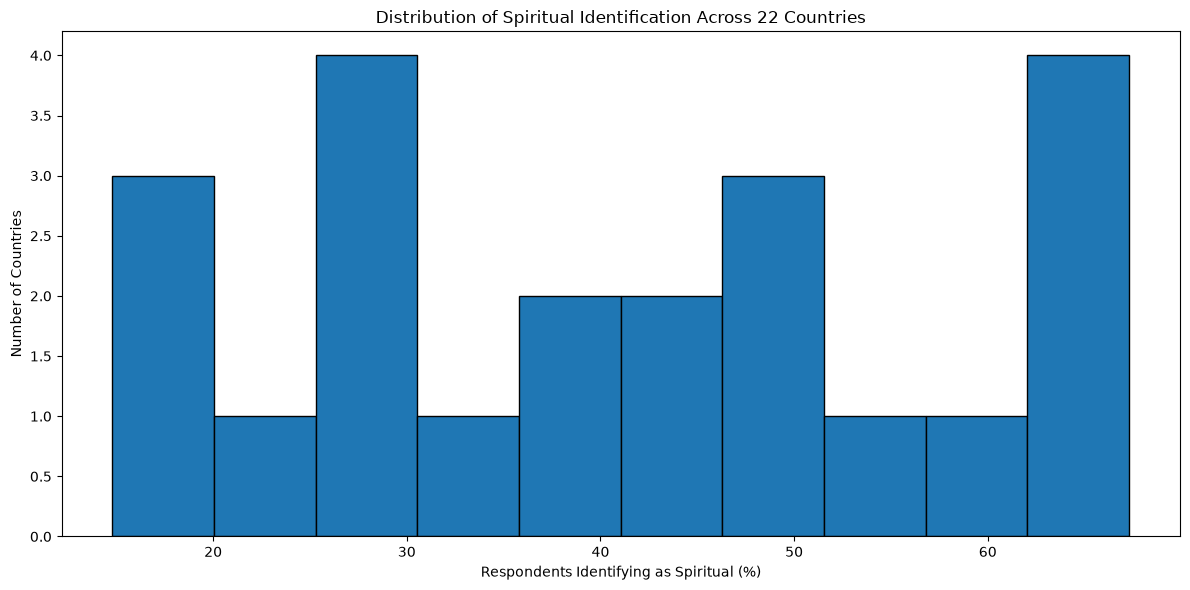

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.hist(
    spiritual_df["spiritual_or_both_pct"],
    bins=10,
    edgecolor="black"
)

plt.title("Distribution of Spiritual Identification Across 22 Countries")
plt.xlabel("Respondents Identifying as Spiritual (%)")
plt.ylabel("Number of Countries")

plt.tight_layout()
plt.show()

**Which feature did you choose, and why is this chart appropriate?**

Your answer:  I chose `spiritual_or_both_pct` because I'm interested in understanding how spiritual self-identification varies across different countries. A histogram is appropriate because this feature contains numerical percentages, and grouping those values into intervals helps reveal patterns in their distribution. It allows me to see whether countries tend to have similar percentages or whether spiritual identification varies significantly.

**In at least one complete sentence, describe what the figure tells you about this feature.** Refer to a visible pattern such as typical values, range, shape, or unusual observations, using values and units where possible. Describe the observations in your dataset without assuming they represent a larger population.

Your interpretation:  The histogram shows that spiritual self-identification varies considerably across the 22 countries in the dataset, ranging from approximately 15% to 65%. There are noticeable concentrations of countries around 25–30% and 60–65%, with other countries distributed between those values. The distribution does not have one clear central peak, suggesting that spiritual identification differs substantially among the countries surveyed. These results describe the countries in this dataset and do not establish how many people worldwide have experienced a spiritual awakening.


### 4. Visualize one categorical feature

Choose a categorical feature and create an appropriate visualization of its distribution. A bar chart of category counts is a good choice; use `.value_counts()` to obtain numeric bar heights from text labels. Include a descriptive title and labels identifying the categories and counts or percentages on the axes. If you choose a pie chart for a small number of categories, label the slices and their shares instead of axes. Explain any excluded missing values or categories, and identify the denominator if you use percentages.


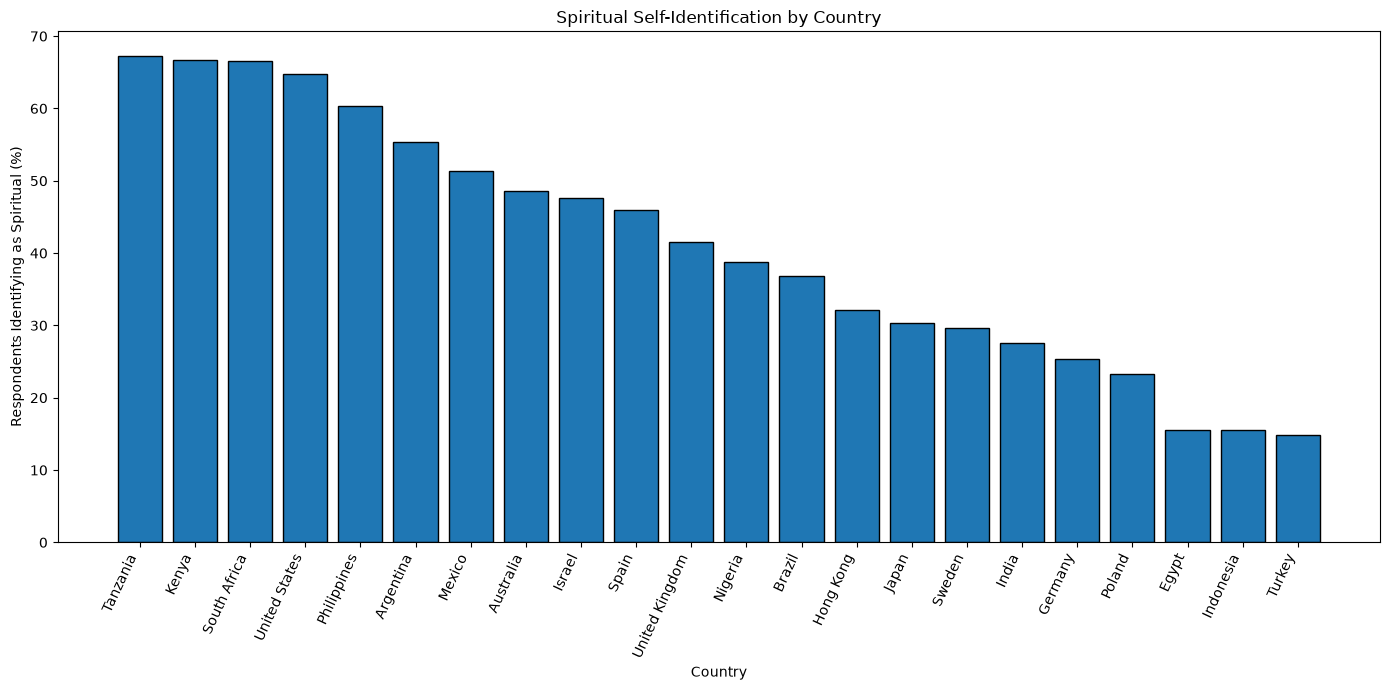

In [22]:
import matplotlib.pyplot as plt

country_spiritual = spiritual_df.sort_values(
    "spiritual_or_both_pct",
    ascending=False
)

plt.figure(figsize=(14, 7))

plt.bar(
    country_spiritual["country"],
    country_spiritual["spiritual_or_both_pct"],
    edgecolor="black"
)

plt.title("Spiritual Self-Identification by Country")
plt.xlabel("Country")
plt.ylabel("Respondents Identifying as Spiritual (%)")
plt.xticks(rotation=65, ha="right")
plt.ylim(bottom=0)

plt.tight_layout()
plt.show()

**Which feature did you choose, and why is this chart appropriate?**

Your answer:  I chose the country feature because I wanted to compare spiritual self-identification across different countries. A bar chart is appropriate because countries are categorical values, and the height of each bar represents the percentage of respondents identifying as spiritual. This makes it easy to compare countries and identify differences in their reported spiritual identities.

**In at least one complete sentence, describe what the figure tells you about this feature.** Identify a meaningful pattern, such as the most or least common category or a difference in counts or shares. Support the interpretation with evidence visible in your figure.

Your interpretation:  The chart shows substantial differences in spiritual self-identification across the 22 countries in this dataset. Tanzania, Kenya, and South Africa have some of the highest percentages, approximately 66–67%, while Turkey, Indonesia, and Egypt have the lowest, around 15–16%. The difference between the highest and lowest countries is approximately 52 percentage points. This suggests considerable variation in how people identify spiritually across the countries surveyed, although it does not establish how many people have experienced a spiritual awakening.


## Reflect on AI assistance

Complete one of the following statements.

**If you used an AI tool:**

- Tool used:
- What I asked it to help with:
- One suggestion I checked against my code, chart, or output:
- What I accepted, modified, or rejected—and why:

**If you did not use an AI tool:**

- I did not use an AI tool for this assignment.
- One resource or troubleshooting strategy I used instead was:


Your response:  
**Tool used:** ChatGPT (OpenAI).

**What I asked it to help with:** I used ChatGPT as a supplemental learning resource to help troubleshoot my Python and Jupyter environment, understand some of the statistical concepts, and work through the data visualization process using the course instructions.

**One suggestion I checked against my code, chart, or output:** I checked the interpretation of the arrival-delay histogram against the actual graph and the numerical results from Pandas. I noticed that the interpretation of arrival delays needed clarification, particularly the difference between early arrivals and flights that arrived late.

**What I accepted, modified, or rejected—and why:** I accepted explanations that matched the course materials and verified results. I questioned and corrected interpretations that did not accurately reflect what the data showed. I also used the provided instructions to guide my code and visualization choices rather than accepting every AI suggestion without checking it.

## Submission checklist

- All code cells run from top to bottom without errors.
- The destination-city bar chart has a descriptive title and labeled axes.
- The default, 5-bin, and 25-bin arrival-delay histograms are included and labeled.
- Both vertical-axis demonstrations are included.
- Every question has one response in its own answer cell.
- The sample questions are answered using the dataset documentation.
- The chosen dataset and its data dictionary are linked and described.
- The feature table includes a description, data type, storage type, and missing-value count for every feature.
- One quantitative and one categorical feature have appropriate labeled visualizations and at least one sentence of interpretation each.
- The chosen CSV is included in the `data` folder with the submitted notebook, and relative paths work.
- The AI-use reflection is complete and honest.
